In [1]:
import pandas as pd

In [2]:
path1 = r'D:\STUDY\internship\dataset\100_10_15_f.ASC'
df1 = pd.read_csv(path1, sep='\\s+', header = None)
df1 = df1[[0,2]]

df1.head()

,0,2
0,0.00000,-0.10740
1,0.00005,-0.15724
2,0.00010,-0.14859
3,0.00016,-0.06766
4,0.00021,-0.06915


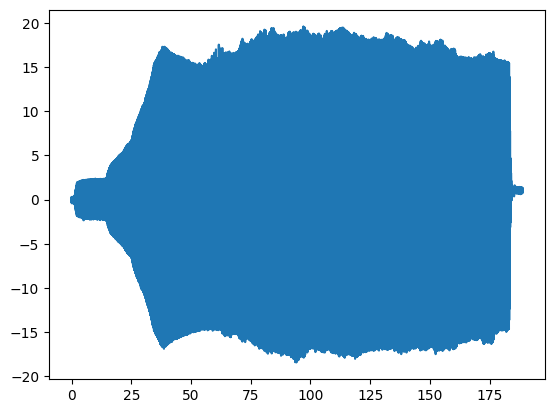

In [3]:
import matplotlib.pyplot as plt
plt.plot(df1[0], df1[2])
plt.show()

In [3]:
df1.drop(df1.index[9512:], inplace=True)
df1.tail()

,4,6
9507,190.14001,0.40790
9508,190.16001,0.30814
9509,190.18001,0.08480
9510,190.20001,0.31614
9511,190.22001,0.34862


In [6]:
df1[6] = df1[6].astype(float)

In [7]:
df1['coe'] = df1[6].apply(lambda x: x/10)
df1.drop(columns=[6], inplace=True)
df1 = df1.rename(columns={0: "Time"})
df1.head()

,4,coe
0,0.00000,0.009862
1,0.02000,0.025955
2,0.04000,0.025972
3,0.06000,0.025761
4,0.08000,0.019096


Motif 在位置 6371 的最相似邻居是位置 6626
异常点在位置 8512 的最相似邻居是位置 3373


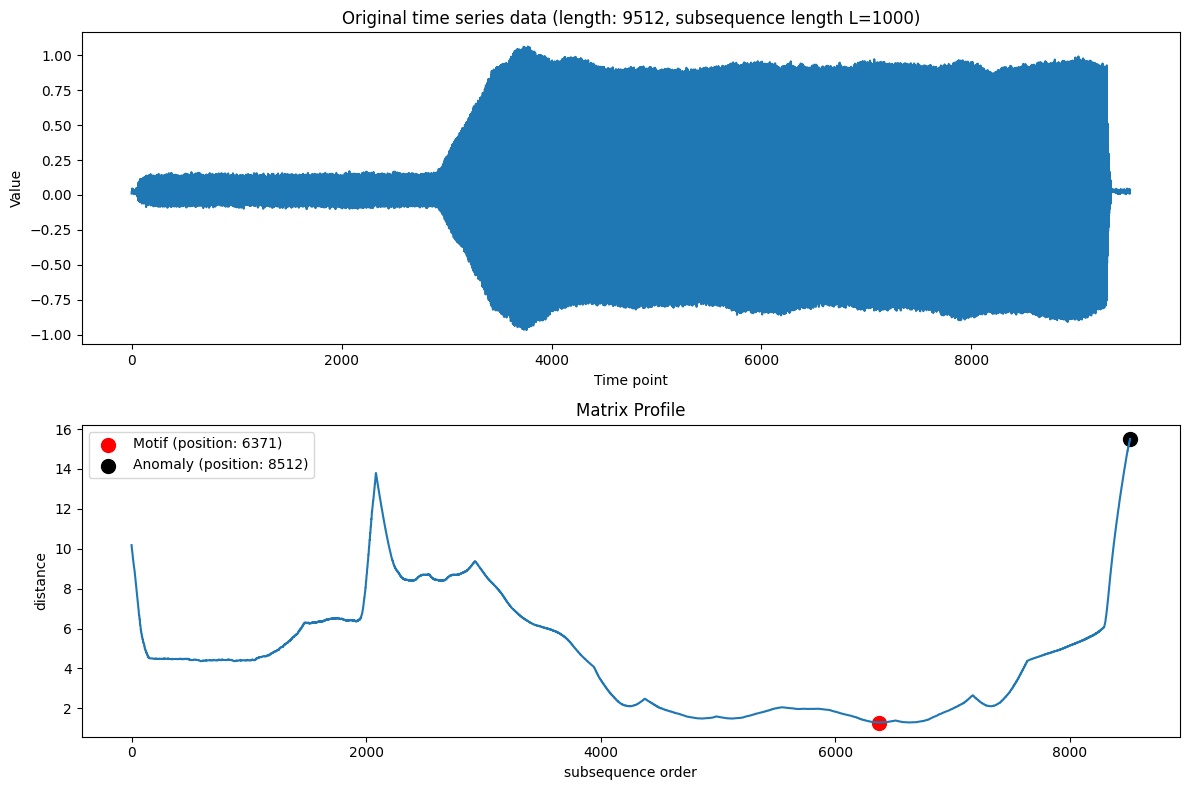

In [18]:
import stumpy
import numpy as np
import matplotlib.pyplot as plt

# 提取时间序列数据
ts = df1['coe'].values  # 确保使用与Matrix Profile相同的列数据

L = 1000 # 子序列长度
matrix_profile = stumpy.stump(ts, L)

# 提取 Matrix Profile 和 Profile Index
mp = matrix_profile[:, 0]
index = matrix_profile[:, 1].astype(int)

# 可视化
plt.figure(figsize=(12, 8))  # 增加高度以适应两个子图

# 子图1: 原始时间序列
plt.subplot(2, 1, 1)
plt.plot(ts)  
plt.title(f"Original time series data (length: {len(ts)}, subsequence length L={L})")
plt.xlabel("Time point")
plt.ylabel("Value")

# 子图2: Matrix Profile
plt.subplot(2, 1, 2)
plt.plot(mp)
plt.title("Matrix Profile")
plt.xlabel("subsequence order")
plt.ylabel("distance")

# 标注重复模式和异常点
motif_location = np.argmin(mp)
anomaly_location = np.argmax(mp)

plt.scatter(motif_location, mp[motif_location], c='red', s=100, label=f"Motif (position: {motif_location})")
plt.scatter(anomaly_location, mp[anomaly_location], c='black', s=100, label=f"Anomaly (position: {anomaly_location})")
plt.legend()

# 调整布局防止标签重叠
plt.tight_layout()

# 打印 Profile Index 信息
print(f"Motif 在位置 {motif_location} 的最相似邻居是位置 {index[motif_location]}")
print(f"异常点在位置 {anomaly_location} 的最相似邻居是位置 {index[anomaly_location]}")

# 显示图形
plt.show()